# Experiment 4: labeled context and the value of CPT

Compare original TabPFN v3 and TabICLv2 with a fixed continued-pretraining (CPT) recipe as labeled context shrinks. Each target table was excluded from its CPT checkpoint. No weights are fitted here. Five outer folds cover all test rows; a separate, fixed validation-label budget supports threshold and calibration rules. This is a context-memory curve, not a curve for the total number of labels acquired.

Does credit CPT change the value of labeled context on an excluded credit table? Dependence on context size is different from variability across repeated contexts of the same size.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
from src.visualize import context_curves as cc
sink = FigureSaver('experiment4/01_context_curves')
report = cp.NotebookReport('Experiment 4: labeled context and the value of CPT', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does credit CPT change the value of labeled context on an excluded credit table? Dependence on context size is different from variability across repeated contexts of the same size.')
study = cc.load_context_study()

DATA: output CreditPFN.zip; modified 2026-10-16T07:14:04+00:00; read only.
Project: output CreditPFN; modified 2026-10-16T08:49:22+00:00; read only.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Fixed checkpoints and evaluation protocol

The CPT reference is the predefined full-parameter experiment-1 recipe, not the best result observed in the sweep. Context prefixes are nested and shared between original and CPT models. Inference views stay fixed within each family.

In [2]:
report.table('Evaluation protocol', cc.protocol_table(study))
report.add('1. Fixed checkpoints and evaluation protocol', 'The 50,000-row cap bounds computation; it is not TabPFN v3’s native limit. The available-pool endpoint is included when distinct. Validation and test rows never enter context.')

,setting,value
0,Models,Explicit TabPFN v3 and TabICLv2 original/CPT p...
1,CPT source,cpt_main_v5; full updates; LR 3e-07; L2-SP 0.0...
2,Dataset exclusion,Each table uses its original experiment-1 held...
3,Outer test folds,5
4,Context rows,"8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, ..."
5,Additional endpoint,"Available context pool, capped at 50,000, with..."
6,Validation labels,"Fixed 20% of each outer training fold, separat..."
7,Test rows,All outer-test rows; unchanged across context ...
8,Inference views,"{'tabpfn': 32, 'tabicl': 8}"
9,Aggregation,Five paired folds per table; equal-weight tabl...


## 2. Completed exports and five-fold support

A completed task supplies one table, model family and outer fold. Its compressed metric export must match the prepared plan and completion receipt. Partially written SQLite journals are recovery evidence and are not counted as completed metric exports.

,task,track,family,partition,dataset,fold,status
0,0,pd,tabpfn,0,Thomas,0,Verified export
1,1,pd,tabpfn,0,Thomas,1,Verified export
2,2,pd,tabpfn,0,Thomas,2,Verified export
3,3,pd,tabpfn,0,Thomas,3,Verified export
4,4,pd,tabpfn,0,Thomas,4,Verified export
...,...,...,...,...,...,...,...
245,245,lgd,tabicl,3,SBA Loans Case (LGD),0,Verified export
246,246,lgd,tabicl,3,SBA Loans Case (LGD),1,Verified export
247,247,lgd,tabicl,3,SBA Loans Case (LGD),2,Verified export
248,248,lgd,tabicl,3,SBA Loans Case (LGD),3,Verified export


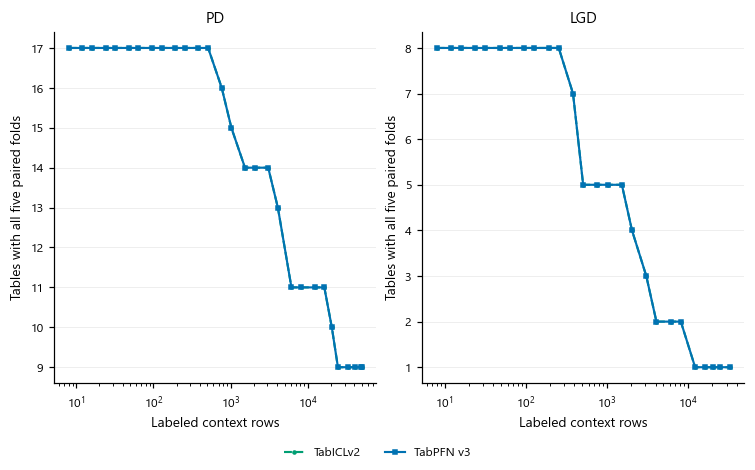

Number of tables with finite original/CPT measurements in all five folds at each nominal context size. Counts reflect both available table sizes and completed exports; they are not live scheduler status. Performance panels separately fix the cohort over their full displayed range.

In [3]:
report.table('Task inventory', study.inventory)
cp.show(sink, cc.plot_context_support(study))
report.add('2. Completed exports and five-fold support', 'Absent exports are unavailable evidence, not zero performance. DATA plans/receipts and project metric exports are both needed. Coverage counts are not live scheduler status.')

## 3. Original and CPT context curves

Separate panels cover context horizons of 128, 2,048 and 50,000 rows. Within each horizon, the same tables must support every displayed context size and both model families. The fixed cohorts prevent changes in table mix from looking like gains from more context. Different horizons can therefore have different table cohorts.

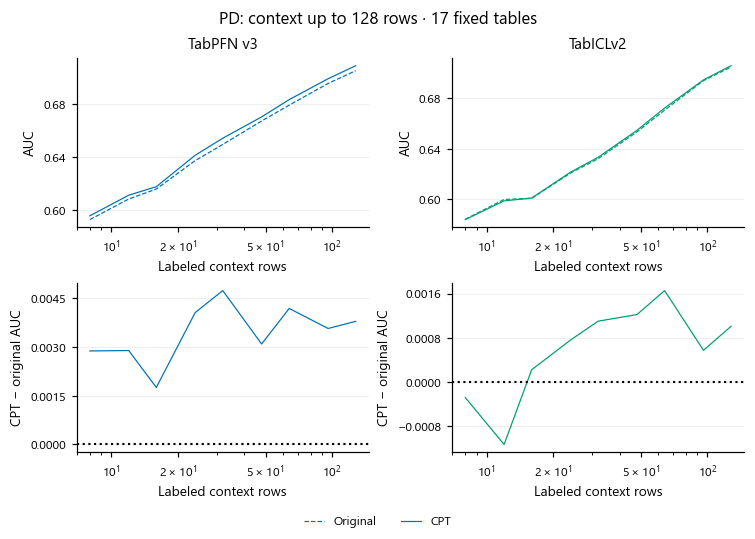

PD. Original and fixed-recipe CPT AUC, with their paired difference below. The same 17 tables contribute at every displayed context size and to both model families. Scores are averaged over five paired outer folds within table, then equally across tables. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree.

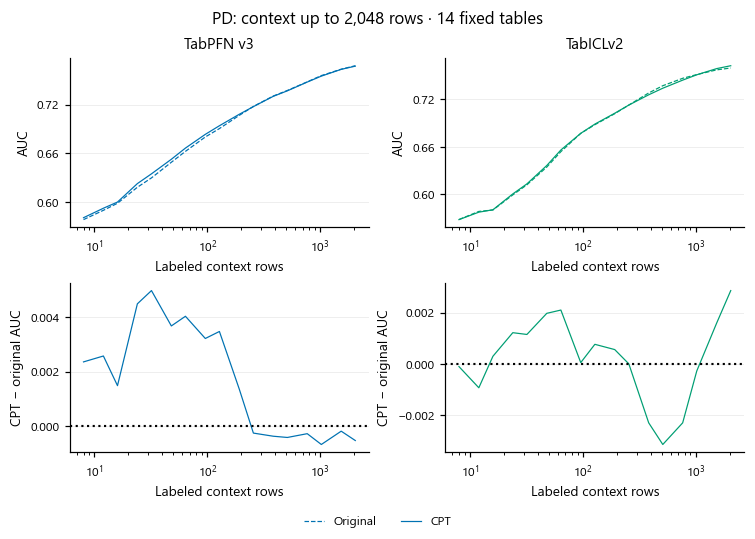

PD. Original and fixed-recipe CPT AUC, with their paired difference below. The same 14 tables contribute at every displayed context size and to both model families. Scores are averaged over five paired outer folds within table, then equally across tables. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree.

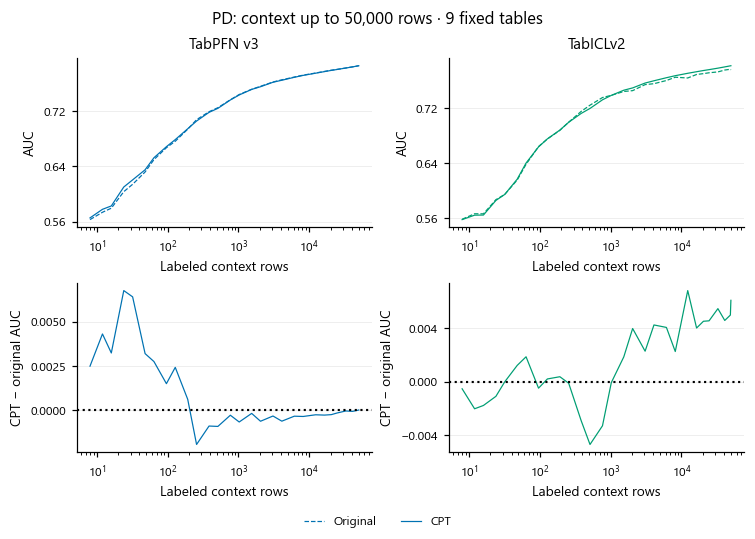

PD. Original and fixed-recipe CPT AUC, with their paired difference below. The same 9 tables contribute at every displayed context size and to both model families. Scores are averaged over five paired outer folds within table, then equally across tables. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree.

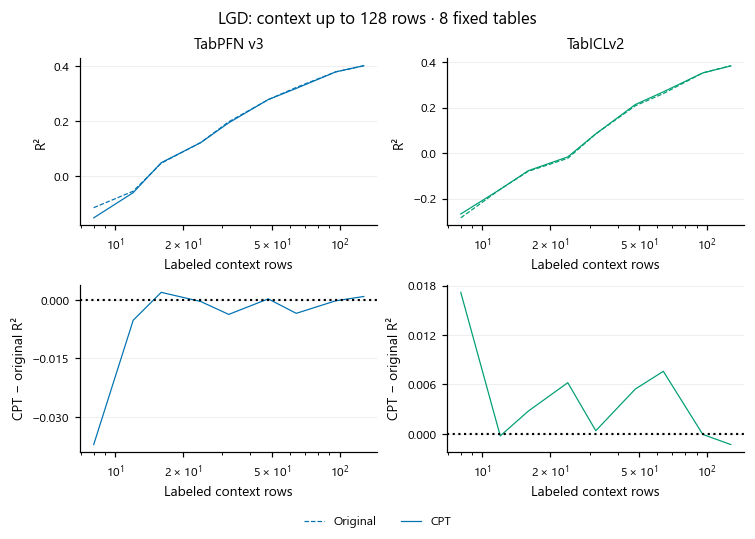

LGD. Original and fixed-recipe CPT R², with their paired difference below. The same 8 tables contribute at every displayed context size and to both model families. Scores are averaged over five paired outer folds within table, then equally across tables. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree.

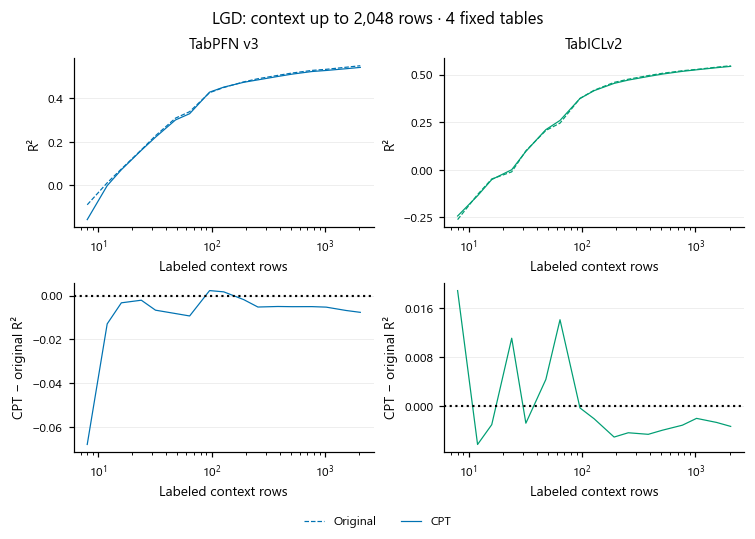

LGD. Original and fixed-recipe CPT R², with their paired difference below. The same 4 tables contribute at every displayed context size and to both model families. Scores are averaged over five paired outer folds within table, then equally across tables. Validation labels have a fixed additional budget; all outer-test rows are unchanged. The horizon identifies the table cohort, so levels across different horizon panels need not agree.

In [4]:
cp.show(sink, cc.plot_context_curves(study))
report.add('3. Original and CPT context curves', 'Primary scores are PD AUC and LGD R². Scores first average the five paired folds within each table, then weight tables equally. Positive differences favor CPT. No figure is generated for a horizon without a complete common cohort.')

## 4. Calibration, errors and inference cost

Retain paired table-level values at every measured context size, including available-pool endpoints. These tables include proper scoring rules, validation-selected F1 and elapsed inference time; their distinct units are preserved.

In [5]:
for metric, table in cc.secondary_tables(study).items():
    report.table(metric+' paired table values', table)
report.add('4. Calibration, errors and inference cost', 'Brier score, log loss, ECE, RMSE, MAE and elapsed-time gains use original minus CPT; AUC, R² and F1 gains use CPT minus original. Timing includes fitting and validation/test prediction, excludes prior CPT training and queue time, and can be affected by fixed execution order. Fold averages are descriptive, not independent table replications.')

,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,pd,tabicl,0,Bondora Peer-to-Peer,8,0.628715,0.624041,-0.004674,roc_auc,5
1,pd,tabicl,0,Bondora Peer-to-Peer,12,0.668714,0.663824,-0.004890,roc_auc,5
2,pd,tabicl,0,Bondora Peer-to-Peer,16,0.680931,0.671145,-0.009786,roc_auc,5
3,pd,tabicl,0,Bondora Peer-to-Peer,24,0.693672,0.683718,-0.009954,roc_auc,5
4,pd,tabicl,0,Bondora Peer-to-Peer,32,0.735079,0.728190,-0.006889,roc_auc,5
...,...,...,...,...,...,...,...,...,...,...
815,pd,tabpfn,3,SBA Loans Case,256,0.977287,0.978468,0.001181,roc_auc,5
816,pd,tabpfn,3,SBA Loans Case,384,0.982855,0.983801,0.000946,roc_auc,5
817,pd,tabpfn,3,SBA Loans Case,512,0.986349,0.986082,-0.000267,roc_auc,5
818,pd,tabpfn,3,SBA Loans Case,768,0.987764,0.987893,0.000129,roc_auc,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,lgd,tabicl,0,PropLGD2,8,-0.508291,-0.519030,-0.010739,r2,5
1,lgd,tabicl,0,PropLGD2,12,-0.112544,-0.139878,-0.027334,r2,5
2,lgd,tabicl,0,PropLGD2,16,-0.147663,-0.188599,-0.040936,r2,5
3,lgd,tabicl,0,PropLGD2,24,-0.012655,-0.057655,-0.045000,r2,5
4,lgd,tabicl,0,PropLGD2,32,0.070566,-0.000418,-0.070984,r2,5
...,...,...,...,...,...,...,...,...,...,...
267,lgd,tabpfn,3,SBA Loans Case (LGD),96,0.637623,0.613443,-0.024181,r2,5
268,lgd,tabpfn,3,SBA Loans Case (LGD),128,0.652347,0.648579,-0.003769,r2,5
269,lgd,tabpfn,3,SBA Loans Case (LGD),192,0.704978,0.701972,-0.003007,r2,5
270,lgd,tabpfn,3,SBA Loans Case (LGD),256,0.720675,0.714794,-0.005881,r2,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,pd,tabicl,0,Bondora Peer-to-Peer,8,0.184988,0.193750,-0.008762,brier_score,5
1,pd,tabicl,0,Bondora Peer-to-Peer,12,0.183541,0.191810,-0.008269,brier_score,5
2,pd,tabicl,0,Bondora Peer-to-Peer,16,0.160572,0.166607,-0.006035,brier_score,5
3,pd,tabicl,0,Bondora Peer-to-Peer,24,0.132215,0.134147,-0.001932,brier_score,5
4,pd,tabicl,0,Bondora Peer-to-Peer,32,0.122625,0.122691,-0.000066,brier_score,5
...,...,...,...,...,...,...,...,...,...,...
815,pd,tabpfn,3,SBA Loans Case,256,0.054445,0.051555,0.002890,brier_score,5
816,pd,tabpfn,3,SBA Loans Case,384,0.045930,0.044319,0.001611,brier_score,5
817,pd,tabpfn,3,SBA Loans Case,512,0.040107,0.039159,0.000948,brier_score,5
818,pd,tabpfn,3,SBA Loans Case,768,0.037052,0.037329,-0.000277,brier_score,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,pd,tabicl,0,Bondora Peer-to-Peer,8,0.556857,0.576512,-0.019655,log_loss,5
1,pd,tabicl,0,Bondora Peer-to-Peer,12,0.556471,0.573962,-0.017491,log_loss,5
2,pd,tabicl,0,Bondora Peer-to-Peer,16,0.496161,0.509129,-0.012968,log_loss,5
3,pd,tabicl,0,Bondora Peer-to-Peer,24,0.427985,0.431322,-0.003337,log_loss,5
4,pd,tabicl,0,Bondora Peer-to-Peer,32,0.402370,0.399040,0.003331,log_loss,5
...,...,...,...,...,...,...,...,...,...,...
815,pd,tabpfn,3,SBA Loans Case,256,0.184002,0.174146,0.009856,log_loss,5
816,pd,tabpfn,3,SBA Loans Case,384,0.155843,0.151707,0.004135,log_loss,5
817,pd,tabpfn,3,SBA Loans Case,512,0.142637,0.139484,0.003153,log_loss,5
818,pd,tabpfn,3,SBA Loans Case,768,0.131819,0.130103,0.001716,log_loss,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,pd,tabicl,0,Bondora Peer-to-Peer,8,0.197795,0.229849,-0.032053,ece,5
1,pd,tabicl,0,Bondora Peer-to-Peer,12,0.180149,0.203127,-0.022978,ece,5
2,pd,tabicl,0,Bondora Peer-to-Peer,16,0.143087,0.160157,-0.017071,ece,5
3,pd,tabicl,0,Bondora Peer-to-Peer,24,0.091697,0.095922,-0.004224,ece,5
4,pd,tabicl,0,Bondora Peer-to-Peer,32,0.065499,0.062636,0.002862,ece,5
...,...,...,...,...,...,...,...,...,...,...
815,pd,tabpfn,3,SBA Loans Case,256,0.034642,0.034776,-0.000133,ece,5
816,pd,tabpfn,3,SBA Loans Case,384,0.028049,0.025921,0.002128,ece,5
817,pd,tabpfn,3,SBA Loans Case,512,0.025190,0.024750,0.000440,ece,5
818,pd,tabpfn,3,SBA Loans Case,768,0.020008,0.022635,-0.002627,ece,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,pd,tabicl,0,Bondora Peer-to-Peer,8,0.307905,0.304141,-0.003763,f1,5
1,pd,tabicl,0,Bondora Peer-to-Peer,12,0.336098,0.334524,-0.001574,f1,5
2,pd,tabicl,0,Bondora Peer-to-Peer,16,0.339601,0.335586,-0.004015,f1,5
3,pd,tabicl,0,Bondora Peer-to-Peer,24,0.351554,0.346793,-0.004761,f1,5
4,pd,tabicl,0,Bondora Peer-to-Peer,32,0.377842,0.374564,-0.003278,f1,5
...,...,...,...,...,...,...,...,...,...,...
815,pd,tabpfn,3,SBA Loans Case,256,0.891879,0.898847,0.006968,f1,5
816,pd,tabpfn,3,SBA Loans Case,384,0.895413,0.896713,0.001301,f1,5
817,pd,tabpfn,3,SBA Loans Case,512,0.917076,0.923676,0.006600,f1,5
818,pd,tabpfn,3,SBA Loans Case,768,0.910333,0.926179,0.015846,f1,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,lgd,tabicl,0,PropLGD2,8,0.328797,0.330514,-0.001717,rmse,5
1,lgd,tabicl,0,PropLGD2,12,0.281982,0.285167,-0.003185,rmse,5
2,lgd,tabicl,0,PropLGD2,16,0.286504,0.291577,-0.005073,rmse,5
3,lgd,tabicl,0,PropLGD2,24,0.270376,0.276108,-0.005733,rmse,5
4,lgd,tabicl,0,PropLGD2,32,0.260782,0.269656,-0.008875,rmse,5
...,...,...,...,...,...,...,...,...,...,...
267,lgd,tabpfn,3,SBA Loans Case (LGD),96,0.153603,0.158541,-0.004939,rmse,5
268,lgd,tabpfn,3,SBA Loans Case (LGD),128,0.150636,0.151522,-0.000886,rmse,5
269,lgd,tabpfn,3,SBA Loans Case (LGD),192,0.138675,0.139527,-0.000852,rmse,5
270,lgd,tabpfn,3,SBA Loans Case (LGD),256,0.134786,0.136321,-0.001535,rmse,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,lgd,tabicl,0,PropLGD2,8,0.266092,0.267581,-0.001488,mae,5
1,lgd,tabicl,0,PropLGD2,12,0.227198,0.229570,-0.002372,mae,5
2,lgd,tabicl,0,PropLGD2,16,0.227937,0.232209,-0.004272,mae,5
3,lgd,tabicl,0,PropLGD2,24,0.216637,0.222047,-0.005409,mae,5
4,lgd,tabicl,0,PropLGD2,32,0.205997,0.213508,-0.007511,mae,5
...,...,...,...,...,...,...,...,...,...,...
267,lgd,tabpfn,3,SBA Loans Case (LGD),96,0.103604,0.110133,-0.006529,mae,5
268,lgd,tabpfn,3,SBA Loans Case (LGD),128,0.098400,0.101379,-0.002979,mae,5
269,lgd,tabpfn,3,SBA Loans Case (LGD),192,0.087601,0.091190,-0.003589,mae,5
270,lgd,tabpfn,3,SBA Loans Case (LGD),256,0.083509,0.088055,-0.004546,mae,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,lgd,tabicl,0,PropLGD2,8,16.551739,0.300993,16.250745,elapsed_seconds,5
1,lgd,tabicl,0,PropLGD2,12,0.313007,0.311024,0.001983,elapsed_seconds,5
2,lgd,tabicl,0,PropLGD2,16,0.344504,0.304955,0.039549,elapsed_seconds,5
3,lgd,tabicl,0,PropLGD2,24,0.310629,0.306877,0.003751,elapsed_seconds,5
4,lgd,tabicl,0,PropLGD2,32,0.309748,0.395929,-0.086181,elapsed_seconds,5
...,...,...,...,...,...,...,...,...,...,...
1087,pd,tabpfn,3,SBA Loans Case,256,2.336282,1.636163,0.700119,elapsed_seconds,5
1088,pd,tabpfn,3,SBA Loans Case,384,2.141696,1.662827,0.478869,elapsed_seconds,5
1089,pd,tabpfn,3,SBA Loans Case,512,2.064556,1.648723,0.415833,elapsed_seconds,5
1090,pd,tabpfn,3,SBA Loans Case,768,2.082313,1.688873,0.393440,elapsed_seconds,5


,track,family,partition,dataset,context_rows,original,adapted,gain,metric,folds
0,lgd,tabicl,0,PropLGD2,8,1.509593,0.170128,1.339465,fit_seconds,5
1,lgd,tabicl,0,PropLGD2,12,0.171513,0.169058,0.002456,fit_seconds,5
2,lgd,tabicl,0,PropLGD2,16,0.163975,0.167039,-0.003064,fit_seconds,5
3,lgd,tabicl,0,PropLGD2,24,0.168103,0.166654,0.001449,fit_seconds,5
4,lgd,tabicl,0,PropLGD2,32,0.164250,0.254894,-0.090644,fit_seconds,5
...,...,...,...,...,...,...,...,...,...,...
1087,pd,tabpfn,3,SBA Loans Case,256,0.317129,0.340931,-0.023802,fit_seconds,5
1088,pd,tabpfn,3,SBA Loans Case,384,0.421072,0.343111,0.077961,fit_seconds,5
1089,pd,tabpfn,3,SBA Loans Case,512,0.335256,0.323938,0.011318,fit_seconds,5
1090,pd,tabpfn,3,SBA Loans Case,768,0.317927,0.328500,-0.010573,fit_seconds,5


## Complete text summary

All displayed numerical values and captions, in section order.

In [6]:
print(report.summary(sink))

Experiment 4: labeled context and the value of CPT

0. Evidence and scope
DATA: output CreditPFN.zip; modified 2026-10-16T07:14:04+00:00; read only.
Project: output CreditPFN; modified 2026-10-16T08:49:22+00:00; read only.
Missing project records are unavailable evidence, not zero effects or failed training.
Does credit CPT change the value of labeled context on an excluded credit table? Dependence on context size is different from variability across repeated contexts of the same size.

1. Fixed checkpoints and evaluation protocol
The 50,000-row cap bounds computation; it is not TabPFN v3’s native limit. The available-pool endpoint is included when distinct. Validation and test rows never enter context.

Table: Evaluation protocol
CSV (first column: row index)
row,setting,value
0,Models,Explicit TabPFN v3 and TabICLv2 original/CPT pairs
1,CPT source,cpt_main_v5; full updates; LR 3e-07; L2-SP 0.003; seed 42; 10000 updates
2,Dataset exclusion,Each table uses its original experiment-1 hel